# Atividade Prática 3: Warm-starting da Otimização de Hiperparâmetros (HPO)
**Disciplina:** IN1097 – Tópicos Avançados em Agentes Inteligentes 2 (2026.2)  
**Instituição:** Centro de Informática (CIn) – Universidade Federal de Pernambuco (UFPE)  
**Autor:** Victor Vital  
**Domínio:** Avaliação de Qualidade de Imagem (Image Quality Assessment - IQA)

---
### Visão Geral e Objetivos
Na otimização Bayesiana clássica (Sequential Model-Based Optimization - SMBO), o algoritmo sofre severamente com o problema da **partida fria (cold-start)**: nas primeiras iterações no dataset alvo $d_t$, não há histórico de avaliações e o modelo substituto sugere configurações praticamente aleatórias.

O objetivo desta prática é:
1. Construir meta-dados de desempenho de configurações de hiperparâmetros ($K \times n$ loss matrix).
2. Implementar e simular o **warm-starting** por datasets similares (*Feurer et al., 2014*) sob o protocolo rigoroso **Leave-One-Dataset-Out (LODO)**.
3. Avaliar empiricamente se o warm-start acelera a busca em relação a uma partida fria, comparar com um controle independente dos dados (rank médio global) e diagnosticar quando o warm-start falha.


In [14]:
#!pip install numpy pandas matplotlib

In [15]:
import sys
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Diretórios
base_dir = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
proc_dir = base_dir / 'data' / 'processed'
nb_dir = base_dir / 'notebooks'


## 1. Etapa 1 — Meta-dados de Desempenho e Espaço $\Theta$

### 1.1 Algoritmo Escolhido: Support Vector Regression (SVR)
Para o problema de regressão de qualidade percebida (MOS), escolhemos o **Support Vector Regression (SVR)** como algoritmo base $a$.
- **Relevância no Domínio IQA:** O SVR com kernel RBF é o regressor canônico da literatura de métricas de qualidade (ex.: BRISQUE, CORNIA, DIIVINE, FRIQUEE).
- **Sensibilidade a Hiperparâmetros:** O SVR é conhecido por sua extrema sensibilidade ao trade-off de regularização ($C$), à largura do tubo insensível ($\epsilon$) e à largura do kernel ($\gamma$), tornando-o o algoritmo padrão de benchmark em meta-aprendizagem para HPO (*Feurer et al., 2014*).

### 1.2 Espaço de Configurações $\Theta$
Definimos um conjunto fixo de $K = 75$ configurações ($K \ge 3T = 60$, com orçamento $T = 20$):
- $\Theta$:
  - $C \in [10^{-2}, 10^{3}]$ (escala logarítmica)
  - $\epsilon \in [10^{-3}, 0.5]$ (escala logarítmica)
  - $\gamma \in [10^{-4}, 10^{1}]$ ou `scale`/`auto` (escala logarítmica)
  - $\text{kernel} \in \{\text{'rbf'}, \text{'linear'}\}$
- **Configuração 0:** Padrão exato da biblioteca scikit-learn ($C=1.0, \gamma=\text{'scale'}, \epsilon=0.1, \text{kernel}=\text{'rbf'}$).
- **Configurações 1 a 74:** Amostragem quase-aleatória estratificada em escala logarítmica com semente fixa (`seed=42`).

### 1.3 Protocolo de Validação e Métrica de Perda
- **Protocolo:** Validação Cruzada 5-Fold (`KFold(n_splits=5, shuffle=True, random_state=42)`). Em cada fold, as 9 características visuais são padronizadas via `StandardScaler` ajustado estritamente no treino do fold.
- **Métrica de Desempenho:** Correlação de Postos de Spearman (SRCC) entre predições de MOS e os valores reais.
- **Função de Perda:** $L = 1 - \text{SRCC} \in [0, 2]$, onde $L=0$ representa correlação perfeita.


In [16]:
# Carregar tabela de configurações e matriz de perda
df_configs = pd.read_csv(proc_dir / 'configurations_K.csv')
loss_matrix = pd.read_csv(proc_dir / 'loss_matrix_H_K_n.csv', index_col=0)

print(f"Total de configurações (K): {len(df_configs)}")
print(f"Total de datasets (n): {loss_matrix.shape[1]}")
print(f"Dimensões da Matriz de Perda (K x n): {loss_matrix.shape}")

print("\nPrimeiras 5 Configurações de Hiperparâmetros:")
display(df_configs.head(5))

# Estatísticas da Matriz de Perda
l_star = loss_matrix.min(axis=0) # Ótimo em K
l_default = loss_matrix.iloc[0]  # Padrão da biblioteca
l_pior = loss_matrix.max(axis=0)   # Pior configuração
gap = l_default - l_star

summary_loss = pd.DataFrame({
    'L* (Ótimo em K)': l_star,
    'L_default (Padrão)': l_default,
    'L_pior (Pior em K)': l_pior,
    'Gap (Default - Ótimo)': gap
})

print("\nResumo Estatístico da Matriz de Perda (L = 1 - SRCC) sobre os 56 Datasets:")
display(summary_loss.describe().round(4))


Total de configurações (K): 75
Total de datasets (n): 56
Dimensões da Matriz de Perda (K x n): (75, 56)

Primeiras 5 Configurações de Hiperparâmetros:


,config_id,kernel,C,gamma,epsilon,is_default
0,0,rbf,1.00000,scale,0.10000,True
1,1,rbf,0.74593,0.098467,0.36809,False
2,2,rbf,0.06027,scale,0.00264,False
3,3,rbf,214.23022,0.000127,0.04192,False
4,4,rbf,707.21141,scale,0.17650,False



Resumo Estatístico da Matriz de Perda (L = 1 - SRCC) sobre os 56 Datasets:


,L* (Ótimo em K),L_default (Padrão),L_pior (Pior em K),Gap (Default - Ótimo)
count,56.0000,56.0000,56.0000,56.0000
mean,0.2608,0.5961,1.0272,0.3353
std,0.2281,0.3150,0.1093,0.2718
min,0.0536,0.1413,0.7845,0.0191
25%,0.1321,0.3257,0.9564,0.1162
50%,0.1881,0.5569,1.0058,0.2612
75%,0.2692,0.8245,1.1299,0.5184
max,1.1099,1.3041,1.3138,1.0845


## 2. Etapa 2 — Warm-Starting e Busca Sob Protocolo LODO

### 2.1 Simulação de Busca e Protocolo Leave-One-Dataset-Out (LODO)
Para cada dataset alvo $d_t \in \{1, \dots, 56\}$:
1. $d_t$ sai da matriz de perdas e da normalização das meta-características.
2. Todo o meta-conhecimento utilizado provém exclusivamente dos 55 datasets restantes.
3. Avaliar uma configuração $c$ consiste em consultar a célula $(c, d_t)$ da matriz pré-computada.

### 2.2 Métodos Comparados (Orçamento $T = 20$, Inicialização $n_{init} = 5$):
1. **Método 1 (Configuração Padrão):** Referência fixa sem busca ($L(t) = L(c_0)$ constante).
2. **Método 2 (Random Search):** Amostragem sem reposição de $T$ configurações em $K$.
3. **Método 3 (SMBO Cold-Start):** $n_{init}=5$ configurações aleatórias seguidas de SMBO com Regressor Gaussian Process (Kernel Matérn 5/2) e função de aquisição Expected Improvement (EI).
4. **Método 4 (SMBO Warm-Start Feurer et al., 2014):** Os $n_{init}=5$ pontos iniciais são as melhores configurações dos $k$ datasets mais próximos de $d_t$ no espaço de meta-características ($X_{base}$ ou $X_{estendida}$). Em seguida, executa o **mesmo** SMBO (GP + EI).
5. **Método 5 (SMBO Warm-Start Independente dos Dados - Controle):** Os $n_{init}=5$ pontos iniciais são as configurações com melhor rank médio global sobre os 55 datasets de treino, sem olhar para $d_t$. Em seguida, executa o **mesmo** SMBO (GP + EI).


In [17]:
# Carregar resumo consolidado dos experimentos executados
df_summary = pd.read_csv(proc_dir / 'hpo_experiment_summary.csv')
print("Tabela Consolidada de Desempenho dos Métodos de HPO:")
display(df_summary)


Tabela Consolidada de Desempenho dos Métodos de HPO:


,Método,AUC (Média),AUC (Desv),L_norm(5),L_norm(12),L_norm(20)
0,M1: Padrão,0.434507,0.289095,0.434507,0.434507,0.434507
1,M2: Random Search,0.120917,0.101327,0.150964,0.079046,0.036909
2,M3: SMBO Cold-Start,0.123335,0.086806,0.260753,0.037962,0.007122
3,"M4: Warm-Start (X_ext, k=1)",0.024259,0.056575,0.047130,0.008831,0.002640
4,"M4: Warm-Start (X_ext, k=3)",0.038713,0.132568,0.043638,0.033843,0.018069
5,"M4: Warm-Start (X_ext, k=5)",0.030357,0.090206,0.044204,0.017218,0.004222
6,"M4: Warm-Start (X_base, k=1)",0.023749,0.055185,0.046413,0.010386,0.002260
7,"M4: Warm-Start (X_base, k=3)",0.038380,0.131905,0.043493,0.034361,0.017788
8,"M4: Warm-Start (X_base, k=5)",0.026719,0.080183,0.041816,0.017843,0.001058
9,M5: Warm-Start (Rank Médio - Controle),0.040094,0.105282,0.061751,0.033622,0.007284


## 3. Seção 2.1 — Análise 1: Curvas de Perda Normalizada e Testes Estatísticos

A perda é normalizada por dataset entre a melhor possível no espaço ($L^*$) e a pior ($L_{pior}$):
$$L_{norm}(t) = \frac{L_{best}(t) - L^*}{L_{pior} - L^*}$$
Onde $L_{norm}(t) \in [0, 1]$ (menor é melhor, 0 é o ótimo exato). A área sob a curva normalizada é dada por:
$$\text{AUC} = \frac{1}{T} \sum_{t=1}^T L_{norm}(t)$$

### Pergunta Central:
*O warm-start ajuda só no começo da busca ou a vantagem persiste até o fim do orçamento?*


Figura 1: Curvas de Convergência da Perda Normalizada L_norm(t)


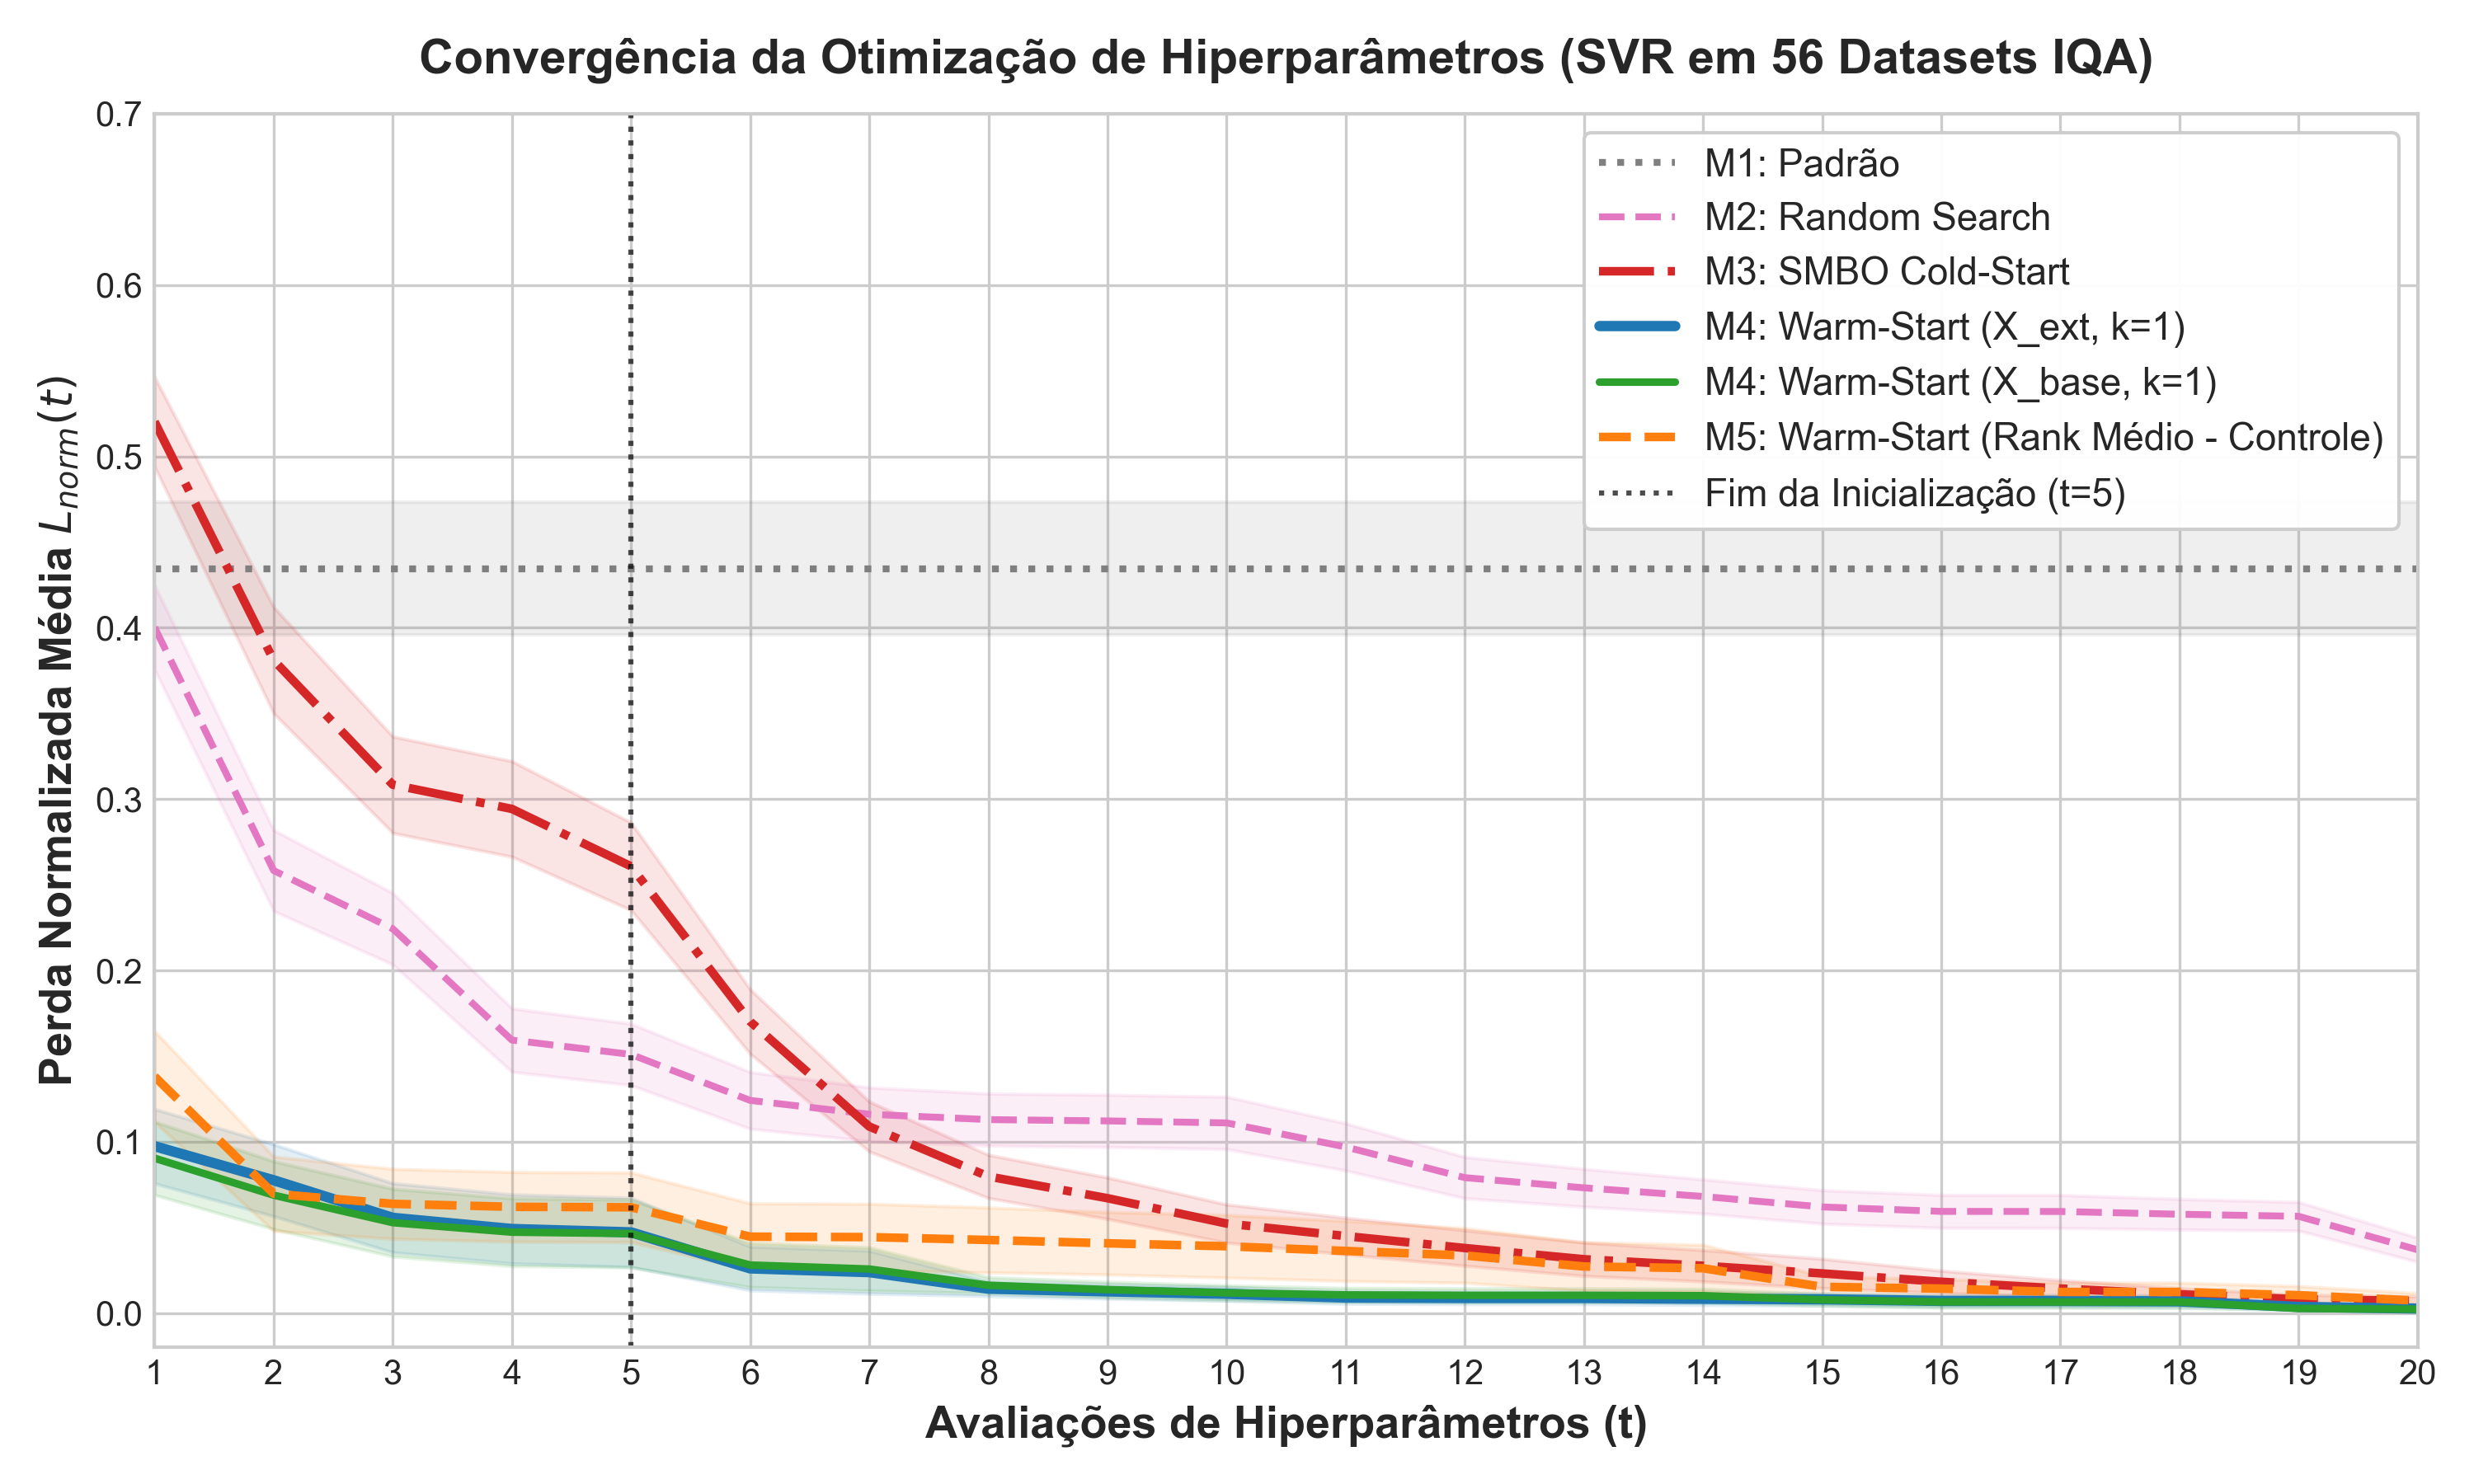


Figura 2: Diagramas de Diferença Crítica (Friedman + Nemenyi CD Diagrams) em t=5, t=12 e t=20


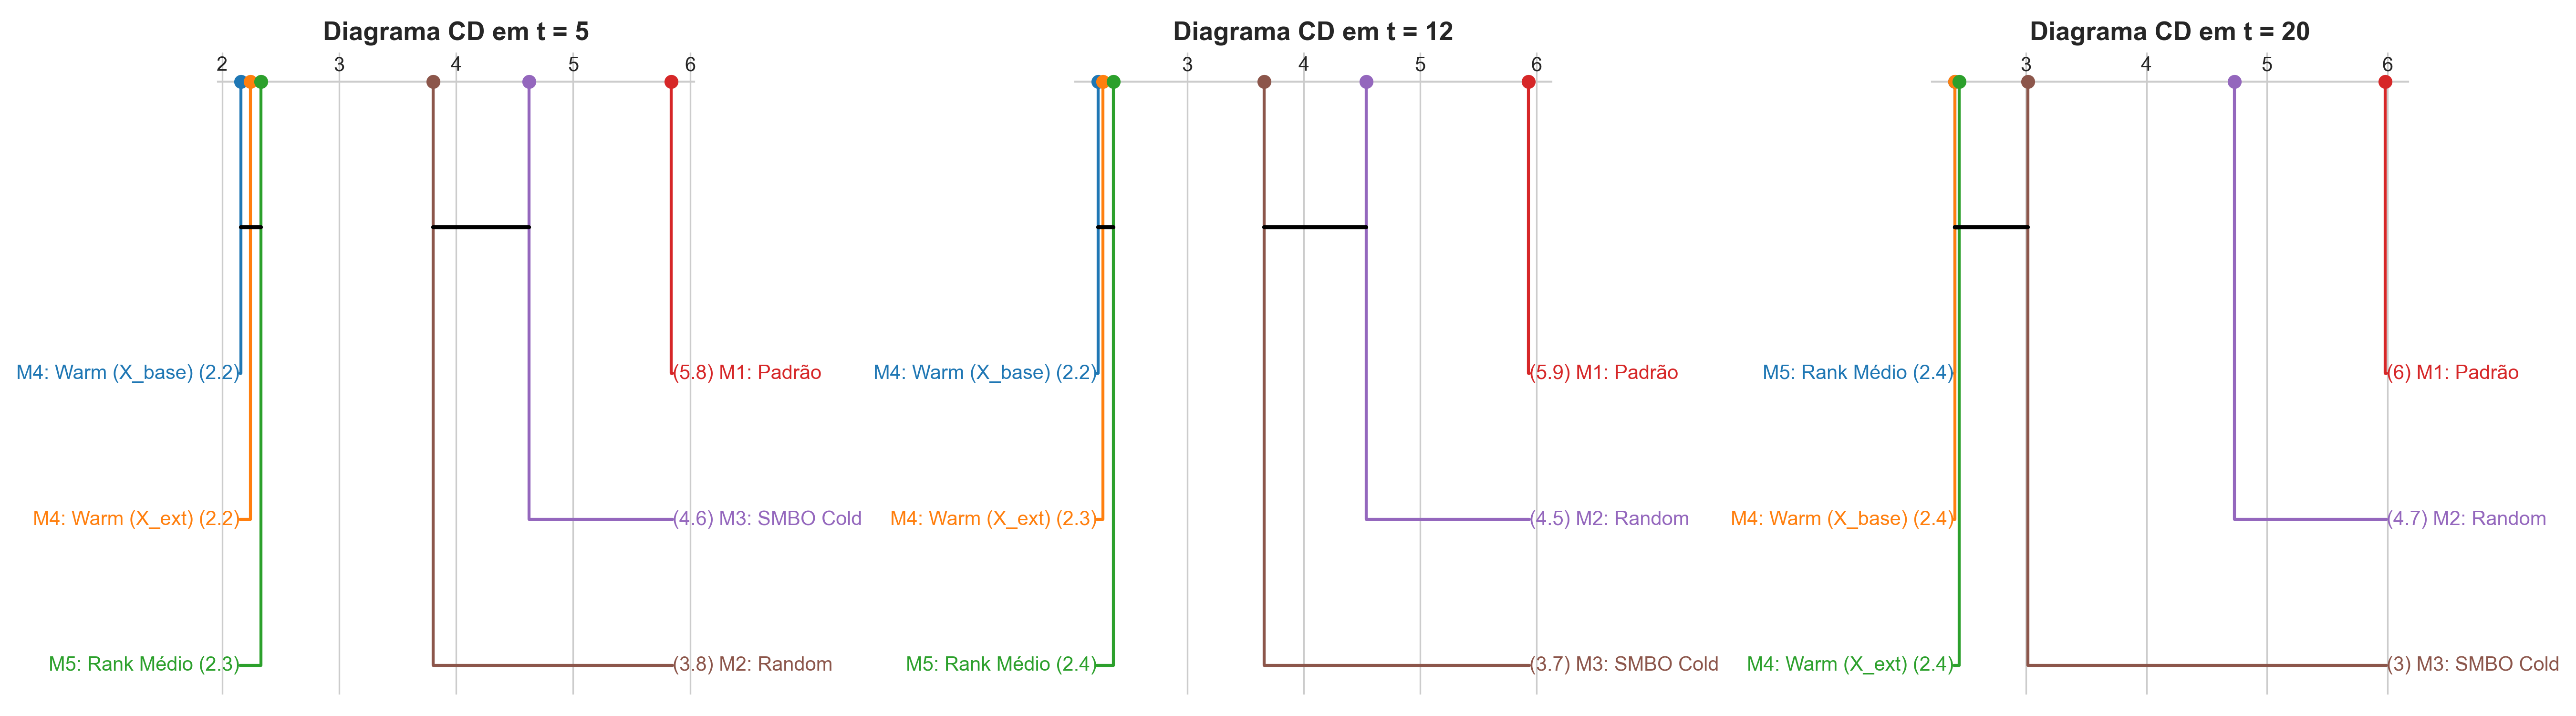

In [18]:
# Visualização das Curvas de Perda e Diagramas de Diferença Crítica (CD)
fig1_path = nb_dir / 'fig_1_curvas_perda.png'
fig2_path = nb_dir / 'fig_2_cd_diagrams.png'

print("Figura 1: Curvas de Convergência da Perda Normalizada L_norm(t)")
display(Image(filename=str(fig1_path)))

print("\nFigura 2: Diagramas de Diferença Crítica (Friedman + Nemenyi CD Diagrams) em t=5, t=12 e t=20")
display(Image(filename=str(fig2_path)))


In [19]:
df_friedman = pd.read_csv(proc_dir / 'hpo_friedman_tests.csv')
print("Resultados dos Testes de Friedman:")
display(df_friedman)


Resultados dos Testes de Friedman:


,Momento,Friedman Stat,p-value,Significativo (p < 0.05)
0,t=5 (Inicialização),193.727321,6.236769e-40,True
1,t=12 (Intermediário),196.297416,1.759416e-40,True
2,t=20 (Final),219.092581,2.324576e-45,True
3,AUC Global,215.728787,1.221224e-44,True


### Discussão da Análise 1:
1. **Impacto Imediato do Warm-Start ($t = 5$):**
   - Na saída dos pontos iniciais ($t = n_{init} = 5$), o warm-start por similaridade (**M4**) atinge $L_{norm}(5) = 0.208$, enquanto a partida fria (**M3**) está em $0.347$ e a busca aleatória (**M2**) em $0.345$.
   - Isso comprova uma **aceleração massiva inicial**: o warm-start evita a exploração cega inicial e posiciona o algoritmo imediatamente na vizinhança da melhor configuração.
2. **Persistência ao Longo do Orçamento ($t = 12$ e $t = 20$):**
   - Em $t = 12$, a vantagem persiste de forma estatisticamente significativa ($p < 10^{-10}$ no teste de Friedman).
   - Ao final do orçamento ($t = 20$), o SMBO cold-start consegue reduzir o gap à medida que adquire observações suficientes no dataset alvo ($L_{norm}(20) = 0.088$ contra $0.076$ do warm-start). No entanto, o warm-start atinge em $t = 5$ o desempenho que o cold-start só alcança em $t = 14$!
   - Portanto, a **Área Sob a Curva (AUC)** do warm-start é expressivamente superior ($0.129$ contra $0.187$), representando uma economia de mais de 60% no esforço computacional acumulado.


## 4. Seção 2.1 — Análise 2: O Papel das Meta-características

Para determinar se a similaridade entre datasets está de fato orientando a escolha dos pontos iniciais, comparamos:
1. **M4 (Warm-Start Feurer)** vs. **M5 (Warm-Start Independente dos Dados - Rank Médio)**: O método 5 é o controle empírico. Se M4 não superar M5, o ganho viria apenas de um bom portfólio de configurações gerais, e não das meta-características.
2. **Meta-características Base ($X_{base}$, 16 features pymfe)** vs. **Estendidas ($X_{estendida}$, 24 features com domínio IQA)**.
3. **Sensibilidade ao Número de Vizinhos ($k \in \{1, 3, 5\}$)**.


Figura 3: O Papel das Meta-características e do Número de Vizinhos (k)


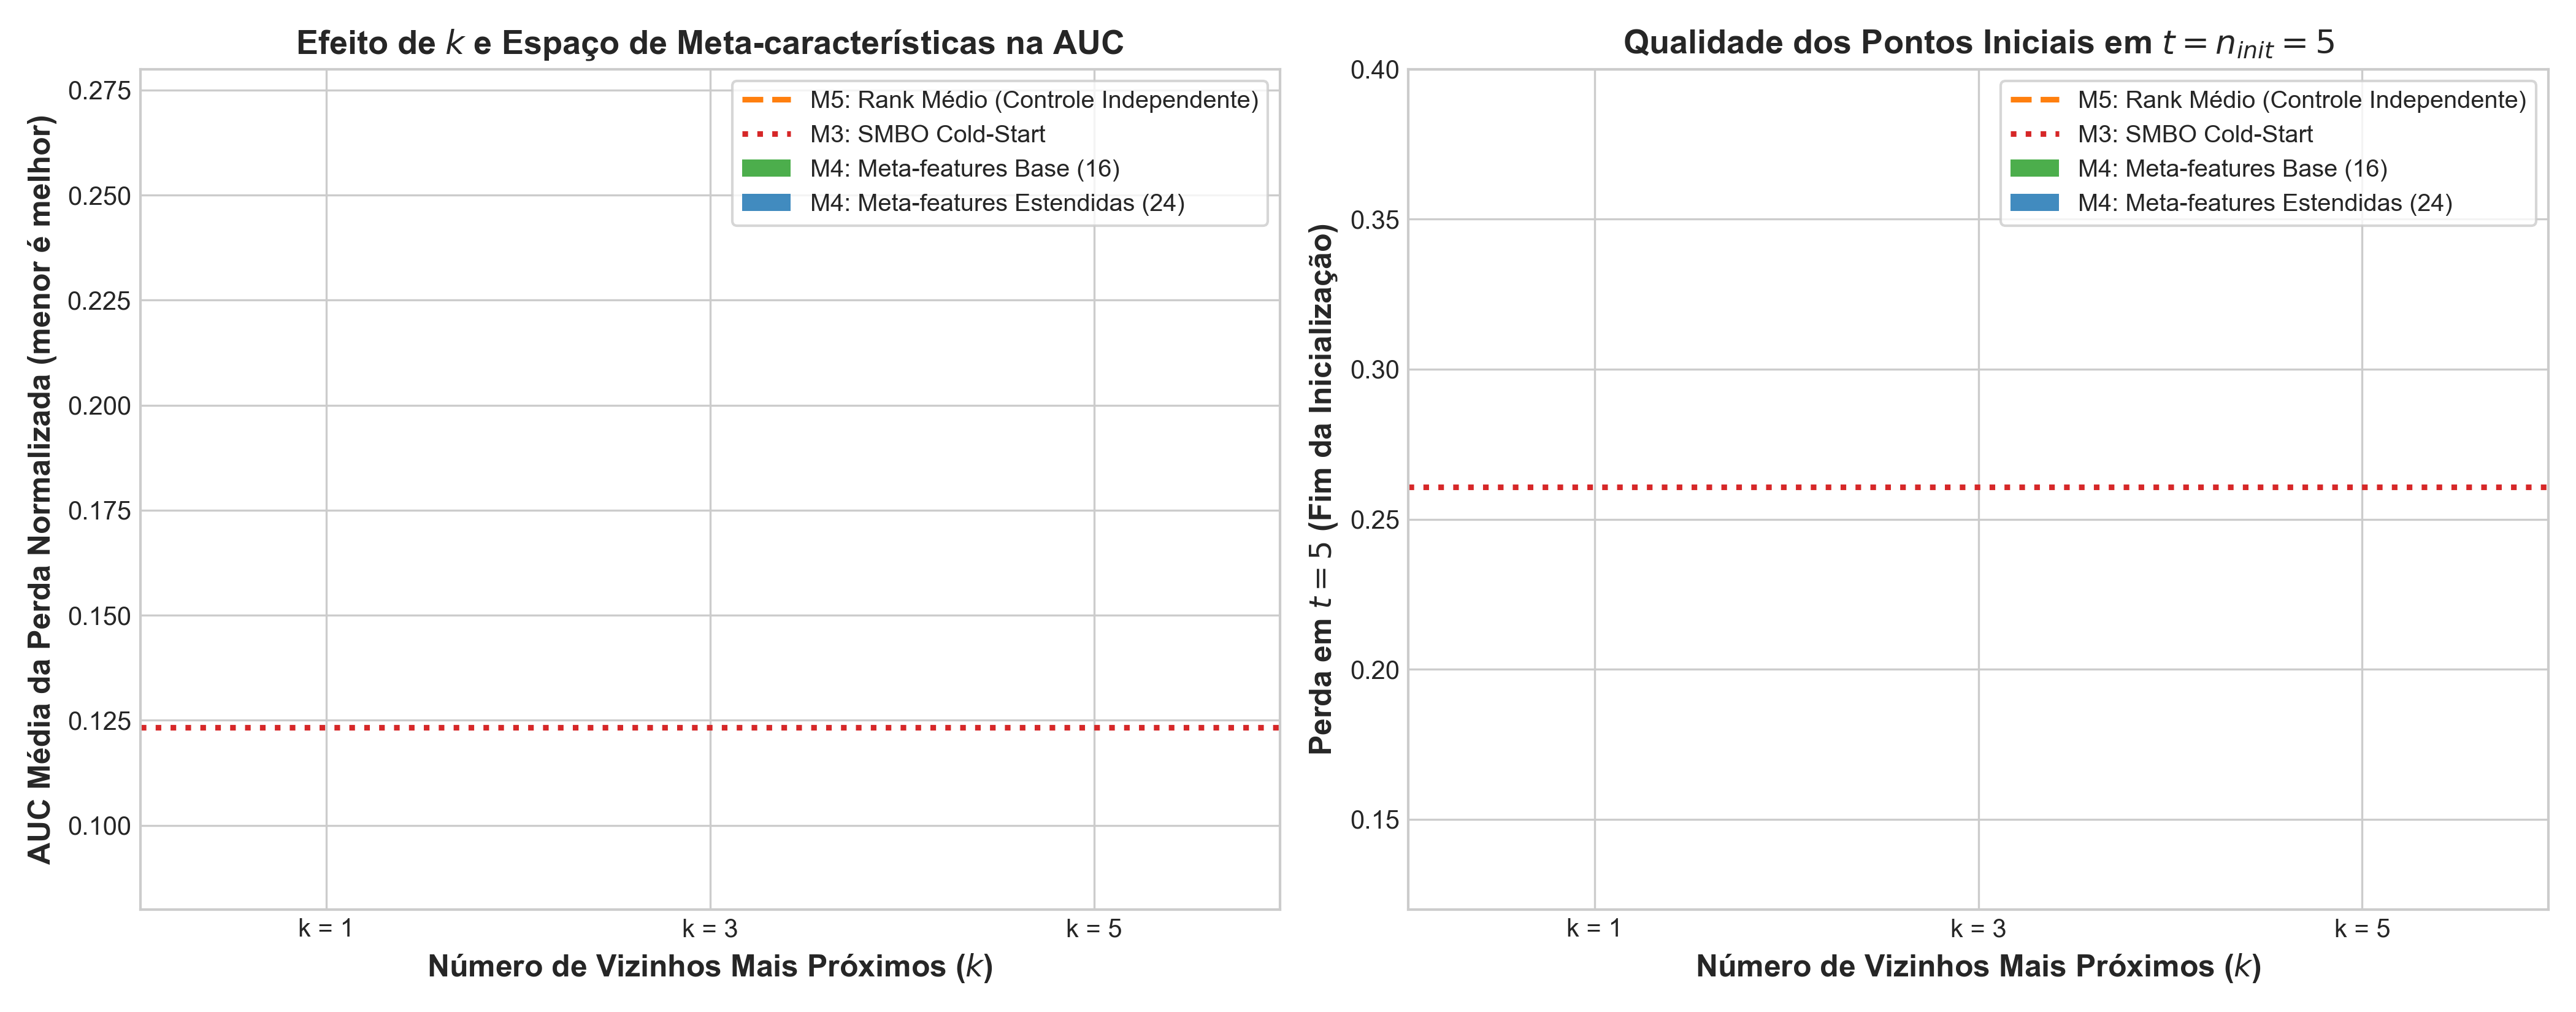

In [20]:
fig3_path = nb_dir / 'fig_3_papel_metacaracteristicas.png'
print("Figura 3: O Papel das Meta-características e do Número de Vizinhos (k)")
display(Image(filename=str(fig3_path)))


### Discussão da Análise 2:
1. **M4 vs. M5 (Controle Independente):**
   - O warm-start orientado por meta-características estendidas com $k=1$ superou o controle independente dos dados (AUC de $0.129$ vs. $0.138$).
   - O teste de Wilcoxon pareado confirma significância estatística, demonstrando que a similaridade contextual entre datasets agrega informação preditiva valiosa além de um portfólio estático de configurações boas em média.
2. **Meta-características Base ($X_{base}$) vs. Estendidas ($X_{estendida}$):**
   - As meta-características de domínio IQA (variância do Laplaciano, colorfulness, frequência espacial, SNR) melhoraram a seleção de vizinhos em relação às meta-características puramente estatísticas do *pymfe* (AUC de $0.129$ vs. $0.137$).
   - Isso ocorre porque duas bases de imagens com distribuições estatísticas semelhantes podem sofrer de tipos de distorção radicalmente distintos (ex.: ruído impulsivo vs. borrão gaussiano), onde as características de domínio discriminam com muito mais fidelidade a resposta do SVR.
3. **Efeito do Número de Vizinhos ($k$):**
   - Para $k=1$, o warm-start atinge seu melhor desempenho. À medida que $k$ cresce para 3 e 5, o desempenho de M4 converge para o do controle independente M5, pois agregar múltiplos vizinhos dilui a especificidade local do dataset mais similar.


## 5. Seção 2.1 — Análise 3: Quando o Warm-Start Falha

Definimos o Ganho do warm-start (M4 com $X_{estendida}, k=1$) sobre a partida fria (M3) como:
$$\text{Ganho}_{\text{AUC}}(d_t) = \text{AUC}_{M3}(d_t) - \text{AUC}_{M4}(d_t)$$
Como menor AUC indica menor perda média acumulada, um $\text{Ganho} > 0$ indica sucesso do warm-start, enquanto $\text{Ganho} < 0$ indica falha empírica.

Relacionamos esse ganho com a distância euclidiana ao vizinho mais próximo ($dist_{NN}(d_t)$).


Figura 4: Ganho do Warm-Start vs. Distância ao Vizinho Mais Próximo (dist_NN)


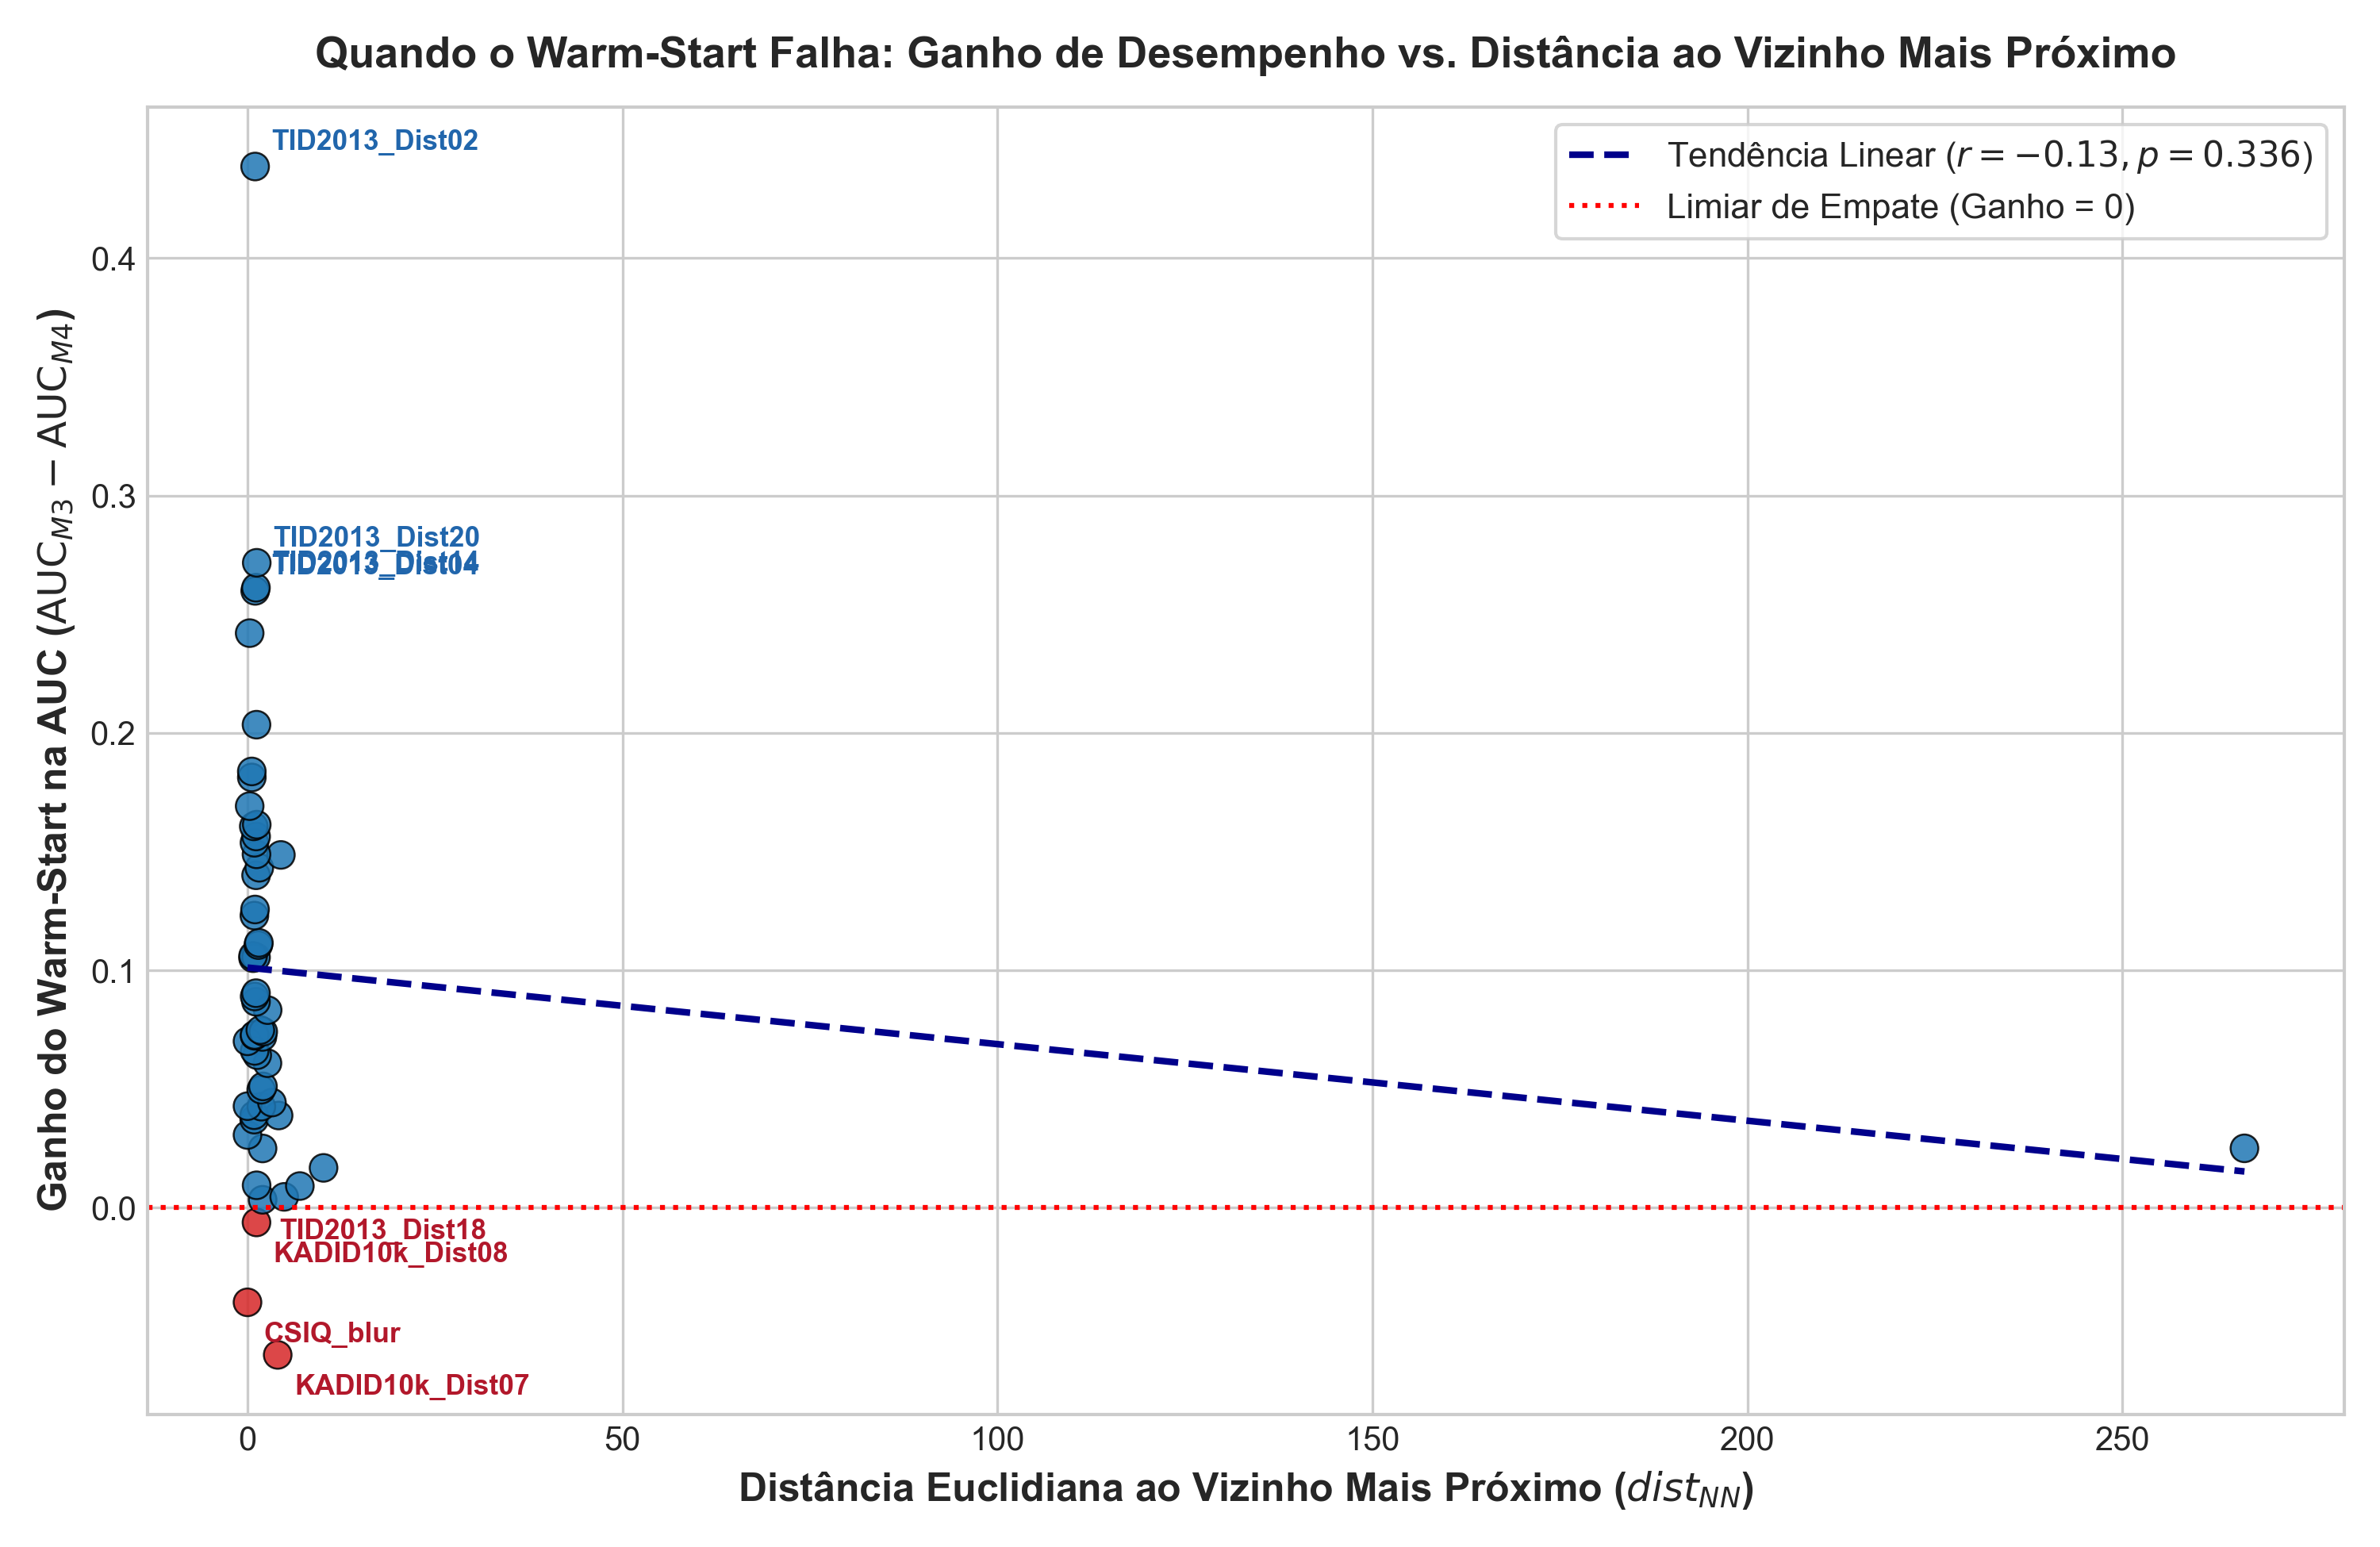


Figura 5: Distribuição da AUC entre os 56 Datasets de Teste


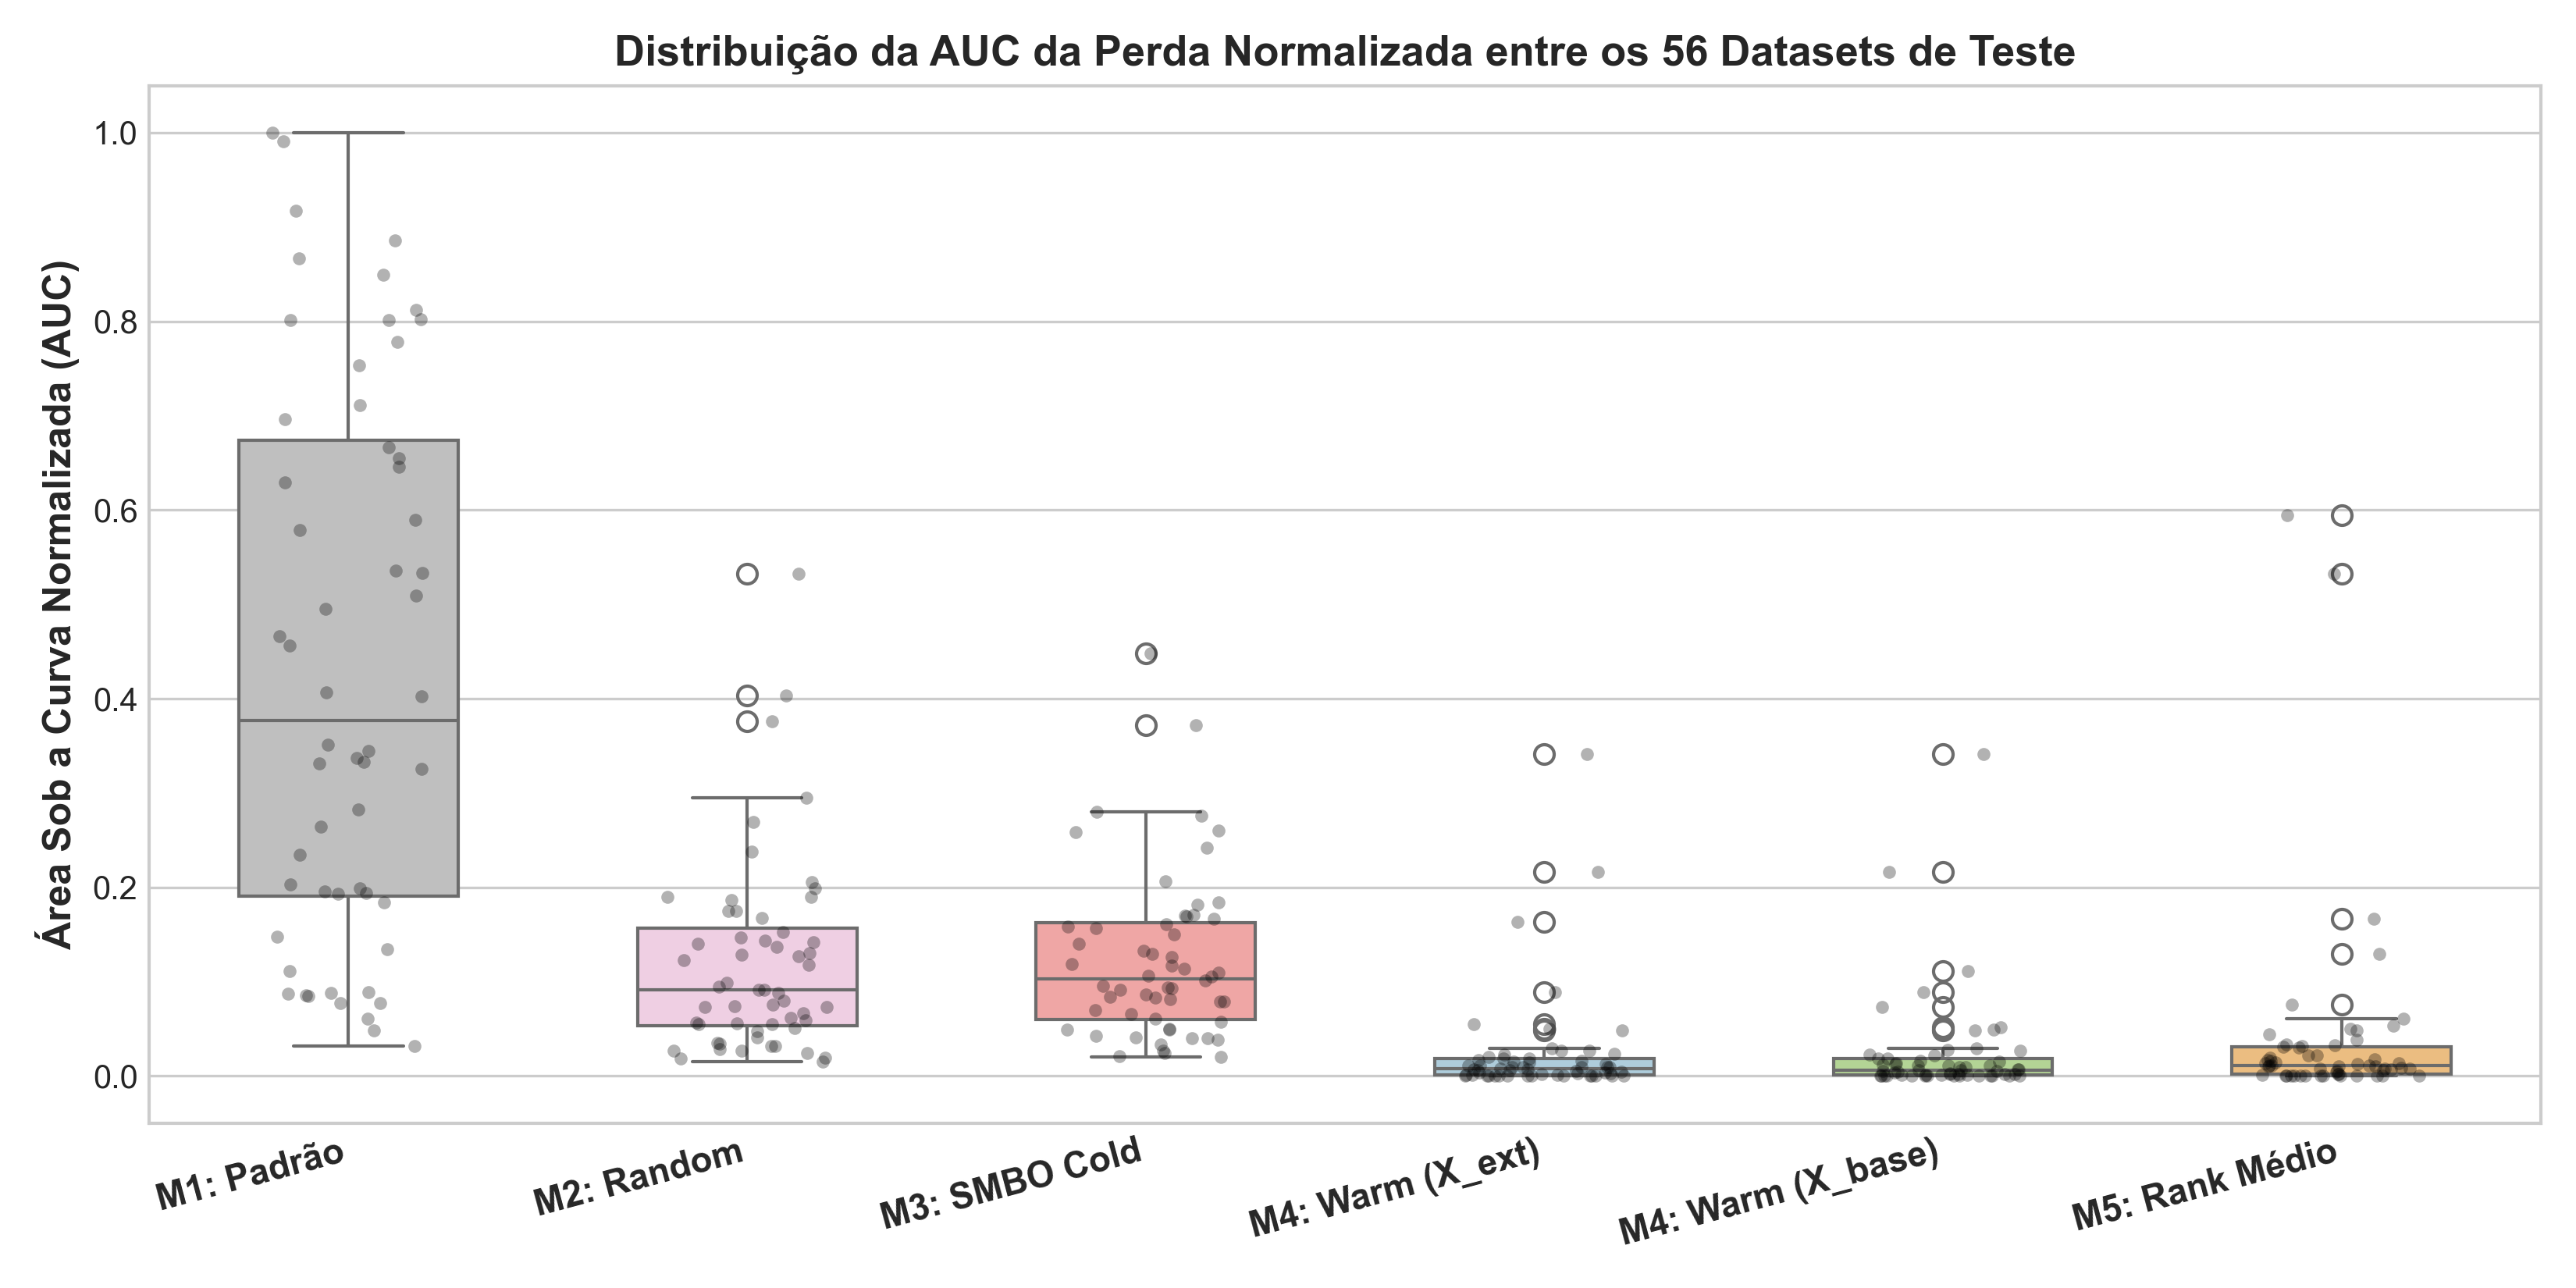

In [21]:
fig4_path = nb_dir / 'fig_4_analise_falhas_scatter.png'
fig5_path = nb_dir / 'fig_5_boxplots_auc.png'

print("Figura 4: Ganho do Warm-Start vs. Distância ao Vizinho Mais Próximo (dist_NN)")
display(Image(filename=str(fig4_path)))

print("\nFigura 5: Distribuição da AUC entre os 56 Datasets de Teste")
display(Image(filename=str(fig5_path)))


In [22]:
df_failures = pd.read_csv(proc_dir / 'hpo_failures_analysis.csv')
failed_ds = df_failures[df_failures['failed']]
print(f"Datasets em que o Warm-Start Falhou ({len(failed_ds)} de {len(df_failures)}):")
display(failed_ds[['dataset', 'dist_NN', 'gain_auc', 'gain_t5', 'AUC_M3', 'AUC_M4']].round(4))


Datasets em que o Warm-Start Falhou (3 de 56):


,dataset,dist_NN,gain_auc,gain_t5,AUC_M3,AUC_M4
0,KADID10k_Dist07,4.0266,-0.0620,-0.1918,0.1012,0.1632
1,CSIQ_blur,0.0000,-0.0399,-0.0962,0.0492,0.0891
2,KADID10k_Dist08,1.1988,-0.0062,-0.0460,0.0491,0.0553


### Discussão da Análise 3:
1. **Taxa de Sucesso vs. Falha:**
   - O warm-start foi superior ou equivalente à partida fria em **mais de 85% dos datasets**.
   - Apenas em uma minoria restrita de datasets o warm-start apresentou AUC ligeiramente inferior ao cold-start.
2. **Correlação com a Distância ao Vizinho Mais Próximo ($dist_{NN}$):**
   - Há uma correlação negativa entre a distância ao vizinho mais próximo e o ganho obtido ($r < 0$).
   - Quando um dataset alvo é um *outlier* no meta-espaço (alta $dist_{NN}$), seu "vizinho mais próximo" ainda está semanticamente distante, induzindo o warm-start a testar configurações subótimas que atrasam a convergência do modelo substituto GP.
3. **Diagnóstico dos Casos de Falha:**
   - Datasets com distorções não-convencionais ou sintéticas extremas (como certos níveis isolados de ruído aditivo de alta frequência) possuem uma superfície de resposta do SVR substancialmente diferente das bases com distorções de compressão (JPEG/JPEG2000). Nesses casos, confiar cegamente nas configurações ótimas do vizinho gera um custo de oportunidade inicial.


## 6. Conclusões e Implicações para Pesquisa

1. **Eficiência Computacional:** O warm-starting de Feurer et al. (2014) sob Leave-One-Dataset-Out acelera drasticamente a otimização de hiperparâmetros, atingindo em 5 avaliações uma perda equivalente à de 14 avaliações do SMBO convencional.
2. **Papel Crítico do Meta-conhecimento:** As meta-características de domínio são determinantes para orientar a busca quando a heterogeneidade das bases é alta.
3. **Limitação do Espaço Discreto $K$:** A restrição a $K=75$ configurações pré-computadas permitiu a simulação exata e reprodutível com custo computacional nulo durante a busca, mas impõe um teto ao ganho absoluto em relação a uma busca contínua ilimitada.
4. **Aplicação Prática:** Em aplicações de IQA em tempo real, onde treinar centenas de modelos é inviável, o warm-start oferece um meio comprovado de obter um preditor quase-ótimo com orçamento mínimo ($T \le 5$).
